# Análisis del run anidado del modelo final

Este notebook analiza `narrow_crop128_fixed_nested`, el run anidado del modelo final `narrow_crop128_fixed` (8 épocas de un programa coseno de 40, con media exponencial de los pesos). Usa solo los ficheros del run (`history.csv`, `predictions_validation.csv`) y el informe de calibración; no carga imágenes ni utiliza `test`.

**Diseño anidado.** Se entrena un modelo por cada par de folds `i-j` (10 modelos), con los otros tres folds como entrenamiento. Cada fold `k` queda así sin ver por los 4 modelos de los pares que lo contienen, y su puntuación fuera de fold es la media de las probabilidades de esos 4 modelos. Es el mismo tipo de puntuación que da el modelo final en `test`, donde se promedian los 5 modelos de fold; por eso la calibración de Platt y el umbral se ajustan sobre ella.

La probabilidad de cada paciente es la media de las probabilidades de sus cortes, y pCR es la clase positiva.

## Preparación

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import roc_auc_score, roc_curve

from breast_cnn.configuration import load_analysis_config
from breast_cnn.data.metadata import load_patients
from breast_cnn.evaluation import (
    apply_platt,
    cohort_baseline,
    model_patient_scores,
    nested_ensemble_scores,
    reliability_bins,
)
from breast_cnn.training.metrics import binary_metrics
from breast_cnn.visualization.nested import (
    plot_model_auc,
    plot_reliability,
    plot_roc_curves,
    plot_score_distribution,
)
from breast_cnn.visualization.plots import plot_learning_curves, save_figure

project_root = Path(os.environ.get("BREAST_CNN_ROOT", "..")).expanduser().resolve()
data_config, analysis_config = load_analysis_config(project_root)
figure_directory = project_root / analysis_config.figures_dir
run_directory = project_root / analysis_config.nested_run
calibration = json.loads(
    (project_root / analysis_config.calibration_report_path).read_text(encoding="utf-8")
)

history = pd.read_csv(run_directory / "history.csv")
predictions = pd.read_csv(run_directory / "predictions_validation.csv")
cohorts = load_patients(project_root, data_config.metadata_dir).set_index("pid")["data"]

scores = nested_ensemble_scores(predictions).set_index("patient_id")
scores["cohort"] = scores.index.map(cohorts)
scores["cohort_baseline"] = cohort_baseline(scores)
scores["calibrated"] = apply_platt(scores["probability"], calibration["platt"])
threshold = calibration["threshold"]
print(
    f"Modelos: {history['fold'].nunique()} · pacientes de validación: {len(scores)} · "
    f"pCR: {scores['label'].sum()}"
)


def show(figure, name):
    save_figure(figure, figure_directory / f"{name}.png")
    plt.close(figure)
    display(Image(filename=str(figure_directory / f"{name}.png"), width=900))

Modelos: 10 · pacientes de validación: 1097 · pCR: 322


## Curvas de aprendizaje de los 10 modelos

Pérdida y AUC por paciente en entrenamiento y validación de cada modelo de par de folds. La validación de cada modelo agrupa sus dos folds excluidos. Todas las curvas se detienen en la época 8, fijada de antemano en `narrow_crop128_fixed`; no hay selección de época con la validación. Las pérdidas de validación forman dos niveles: los 4 pares que contienen el fold 3 tienen más cortes con pCR en validación (31 % frente a 28 %) y un `pos_weight` mayor (2,5–2,6 frente a 2,3), y la pérdida ponderada multiplica por ese peso cada corte positivo. Por eso la pérdida no es comparable entre modelos, y el AUC sí.

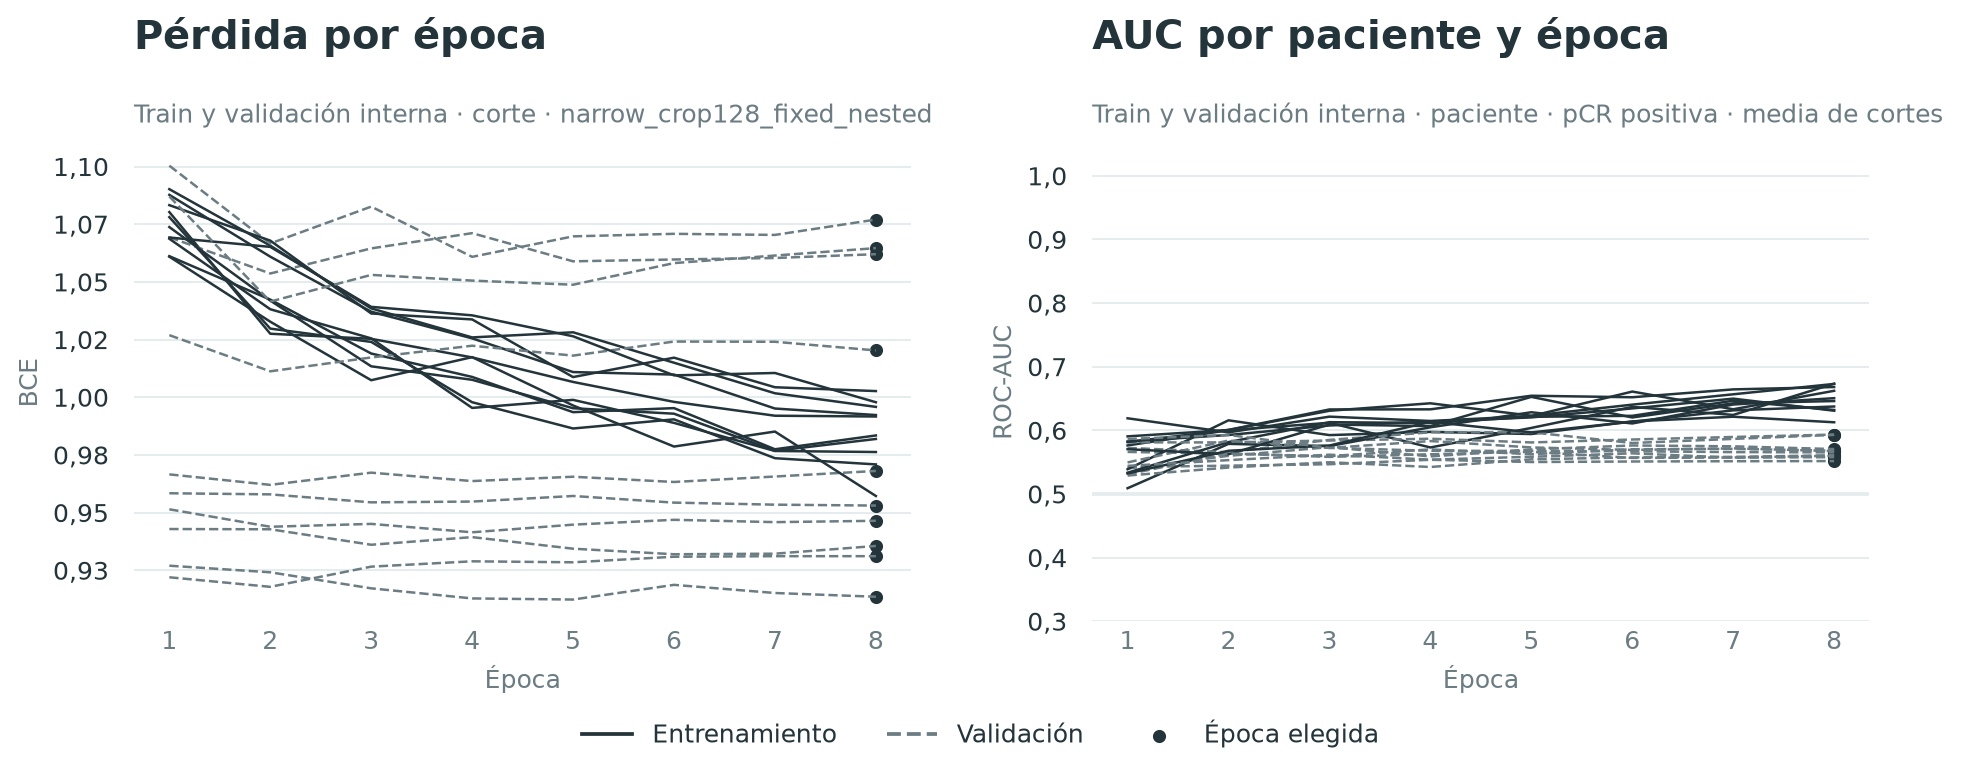

,train_patient_auc,validation_patient_auc,gap
fold,,,
0-1,0.631,0.568,0.063
0-2,0.673,0.571,0.103
0-3,0.673,0.552,0.121
0-4,0.613,0.593,0.019
1-2,0.651,0.593,0.058
1-3,0.668,0.561,0.107
1-4,0.632,0.567,0.065
2-3,0.646,0.560,0.086
2-4,0.637,0.565,0.072


In [2]:
show(
    plot_learning_curves(history, "narrow_crop128_fixed_nested", dict.fromkeys(history["fold"], 8)),
    "learning_curves_nested_validation",
)
last = history.loc[history["epoch"].eq(history["epoch"].max())]
display(
    last[["fold", "train_patient_auc", "validation_patient_auc"]]
    .assign(gap=last["train_patient_auc"] - last["validation_patient_auc"])
    .set_index("fold")
    .round(3)
)

## AUC de cada modelo frente al ensemble

En cada fold se compara el AUC por paciente de los 4 modelos que no lo vieron, por separado, con el AUC de la media de sus probabilidades. Si los modelos cometen errores distintos, la media ordena mejor a las pacientes que cada modelo individual. La línea base de cohorte asigna a cada paciente la proporción de pCR de su cohorte en los otros cuatro folds: indica cuánto AUC se obtiene solo reconociendo la cohorte.

,ensemble,cohort_baseline,single_model_mean
0,0.576,0.534,0.570
1,0.605,0.526,0.590
2,0.586,0.538,0.580
3,0.534,0.593,0.530
4,0.585,0.554,0.577
mean,0.577,0.549,0.570
std,0.026,0.027,0.023


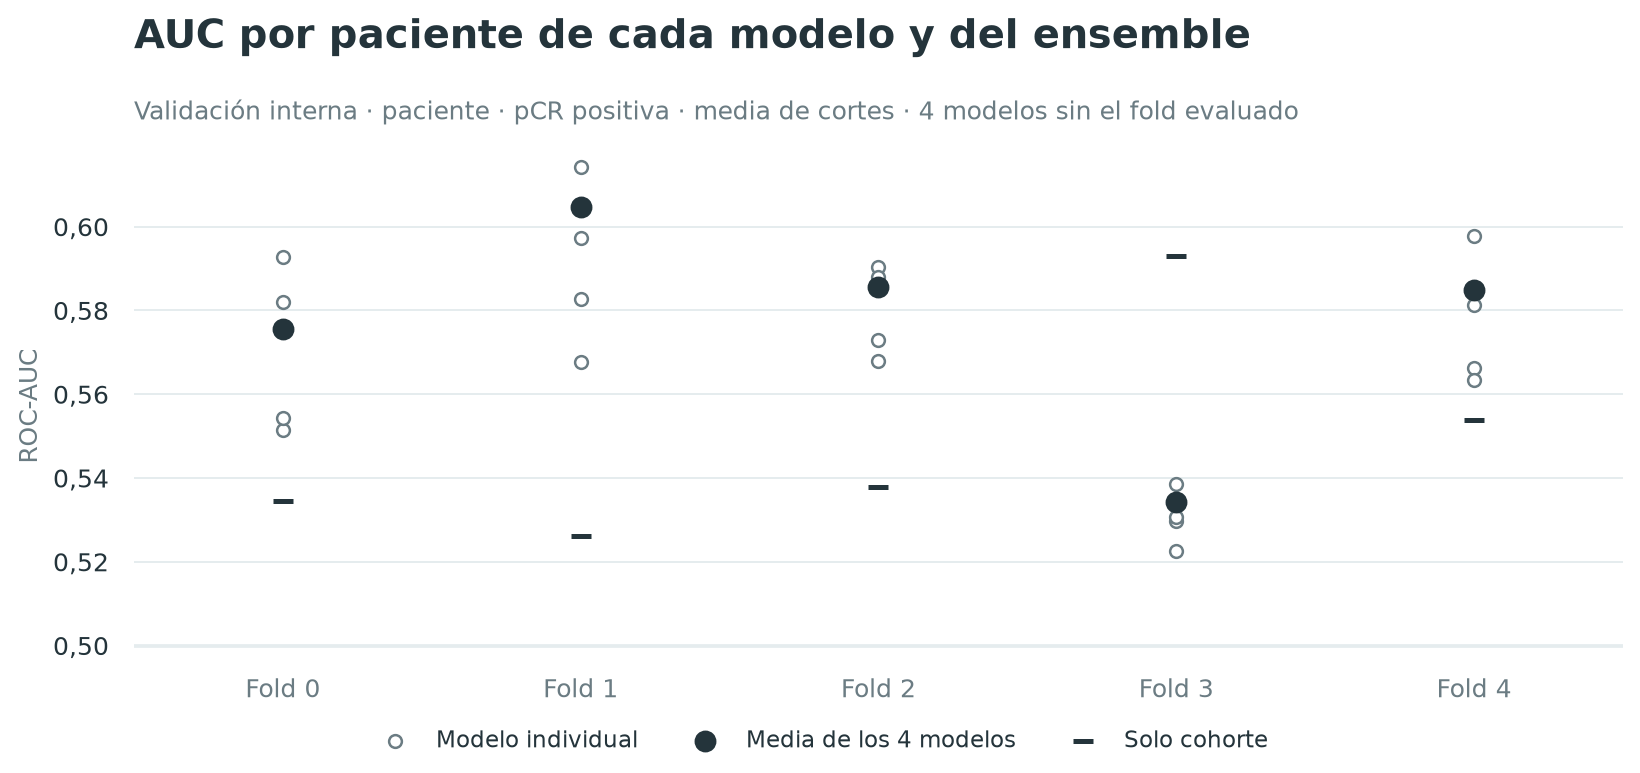

In [3]:
models = (
    model_patient_scores(predictions)
    .groupby(["fold", "model"])
    .apply(lambda rows: roc_auc_score(rows["label"], rows["probability"]), include_groups=False)
    .rename("auc")
    .reset_index()
)
folds = scores.groupby("fold").apply(
    lambda rows: pd.Series(
        {
            "ensemble": roc_auc_score(rows["label"], rows["probability"]),
            "cohort_baseline": roc_auc_score(rows["label"], rows["cohort_baseline"]),
        }
    ),
    include_groups=False,
)
folds["single_model_mean"] = models.groupby("fold")["auc"].mean()
display(pd.concat([folds, folds.agg(["mean", "std"])]).round(3))
show(plot_model_auc(models, folds), "model_auc_nested_validation_patient")

## Curva ROC y punto de operación

La curva ROC agrupa las 1.097 pacientes de los cinco folds. El AUC agrupado puede diferir de la media por fold, porque mezcla puntuaciones de modelos distintos. El punto marcado es el umbral elegido sobre la probabilidad calibrada: el menor valor que deja una especificidad de al menos el 90 % (como mucho un 10 % de pacientes sin pCR clasificadas como pCR). La calibración de Platt es monótona creciente, por lo que no cambia la curva ROC; el umbral se puede situar sobre ella.

n                    1097.000
positives             322.000
auc                     0.574
sensitivity             0.149
specificity             0.901
balanced_accuracy       0.525
dtype: float64

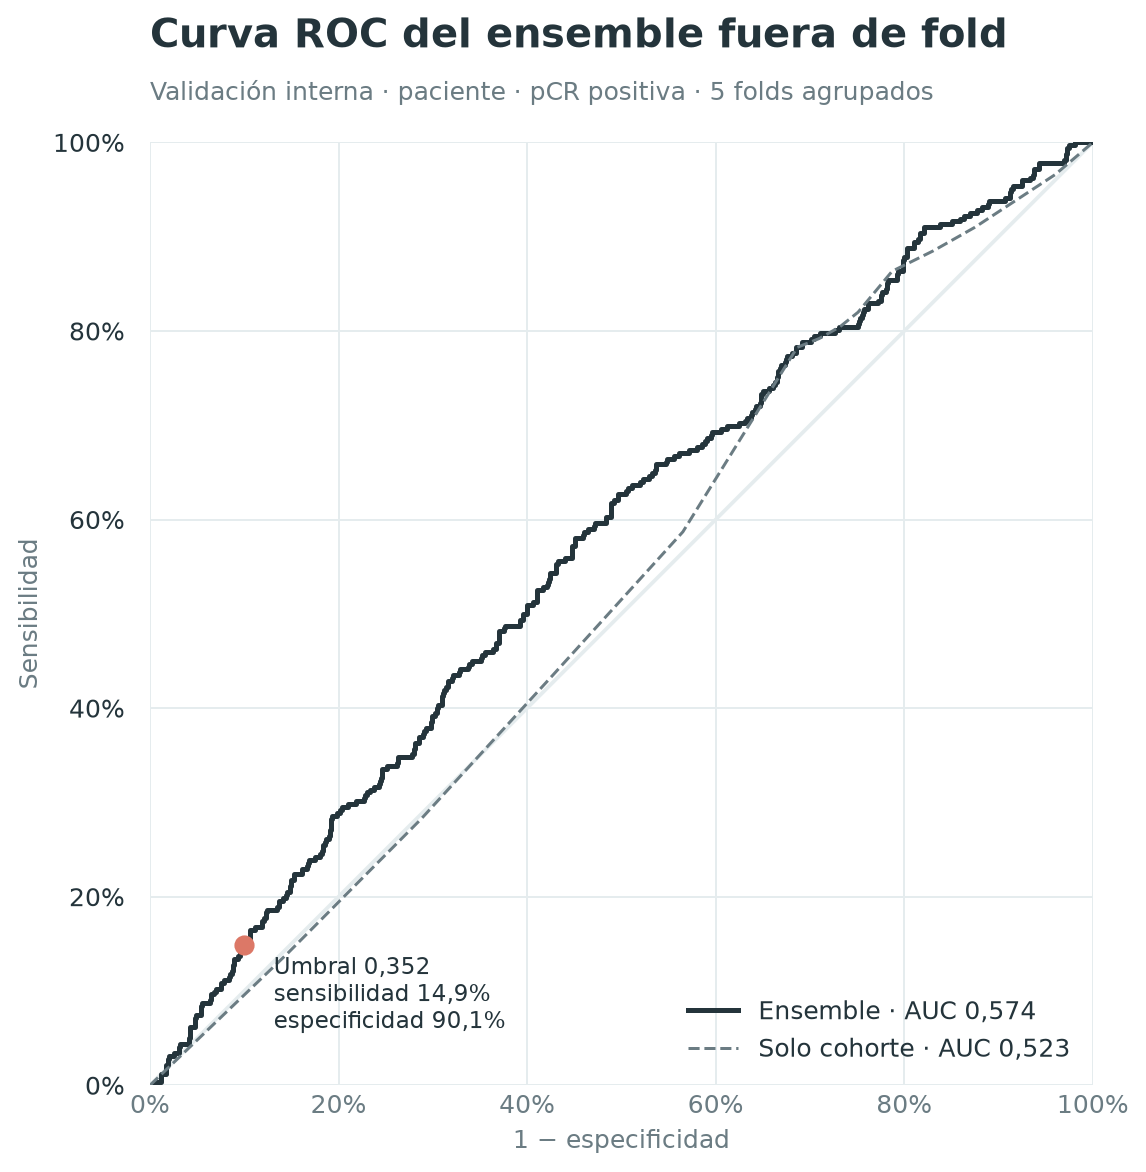

In [4]:
curves = {}
for name, column in (("Ensemble", "probability"), ("Solo cohorte", "cohort_baseline")):
    fpr, tpr, _ = roc_curve(scores["label"], scores[column])
    curves[name] = (fpr, tpr, roc_auc_score(scores["label"], scores[column]))
operating = binary_metrics(scores["label"], scores["calibrated"], threshold)
display(pd.Series(operating).round(3))
show(
    plot_roc_curves(curves, (1 - operating["specificity"], operating["sensitivity"]), threshold),
    "roc_nested_validation_patient",
)

## Calibración de la probabilidad

Una probabilidad está calibrada si, entre las pacientes a las que se asigna un 30 %, alrededor del 30 % alcanza pCR. Se agrupan las pacientes en deciles de probabilidad y se compara la probabilidad media predicha con la proporción observada de pCR; los puntos de un modelo calibrado caen sobre la diagonal.

La probabilidad sin calibrar procede de una pérdida ponderada con `pos_weight = N0 / N1`, que equivale a entrenar como si las clases estuvieran equilibradas, de modo que sobrestima la proporción de pCR. El ajuste de Platt es una regresión logística de la etiqueta sobre el logit de esa probabilidad; una pendiente menor que 1 indica que la puntuación original es demasiado extrema para su capacidad de ordenación.

{'slope': 0.6407012714813944, 'intercept': -0.7786172421388746, 'slope_constrained': False}


predicted  observed    n
score        bin                          
Sin calibrar 0        0.273     0.200  110
             1        0.358     0.255  110
             2        0.395     0.239  109
             3        0.428     0.273  110
             4        0.452     0.245  110
             5        0.475     0.339  109
             6        0.502     0.355  110
             7        0.527     0.312  109
             8        0.555     0.345  110
             9        0.616     0.373  110
Platt        0        0.196     0.200  110
             1        0.240     0.255  110
             2        0.259     0.239  109
             3        0.276     0.273  110
             4        0.288     0.245  110
             5        0.301     0.339  109
             6        0.316     0.355  110
             7        0.330     0.312  109
             8        0.346     0.345  110
             9        0.384     0.373  110

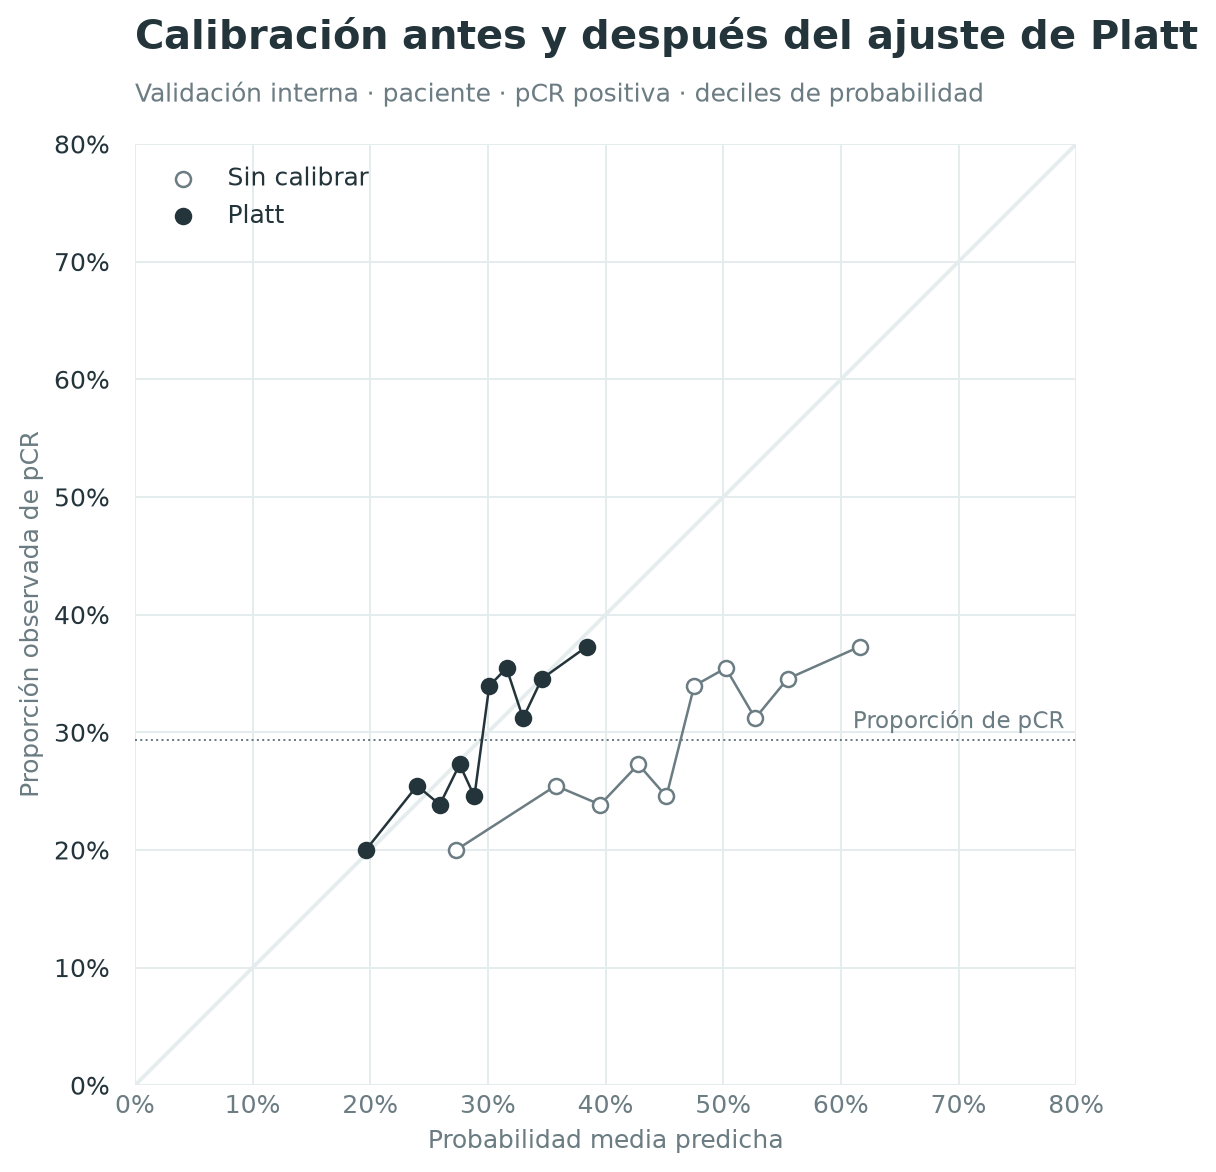

In [5]:
print(calibration["platt"])
bins = {
    "Sin calibrar": reliability_bins(scores["label"], scores["probability"], 10),
    "Platt": reliability_bins(scores["label"], scores["calibrated"], 10),
}
display(pd.concat(bins, names=["score"]).round(3))
show(plot_reliability(bins, scores["label"].mean()), "reliability_nested_validation_patient")

## Distribución de la probabilidad calibrada por clase

Cada histograma está normalizado dentro de su clase. El solapamiento de ambas distribuciones es la expresión visual de un AUC próximo a 0,57: para la mayoría de las pacientes, la probabilidad asignada es similar con o sin pCR. A la derecha del umbral solo queda la cola de puntuaciones altas, donde la proporción de pCR es mayor.

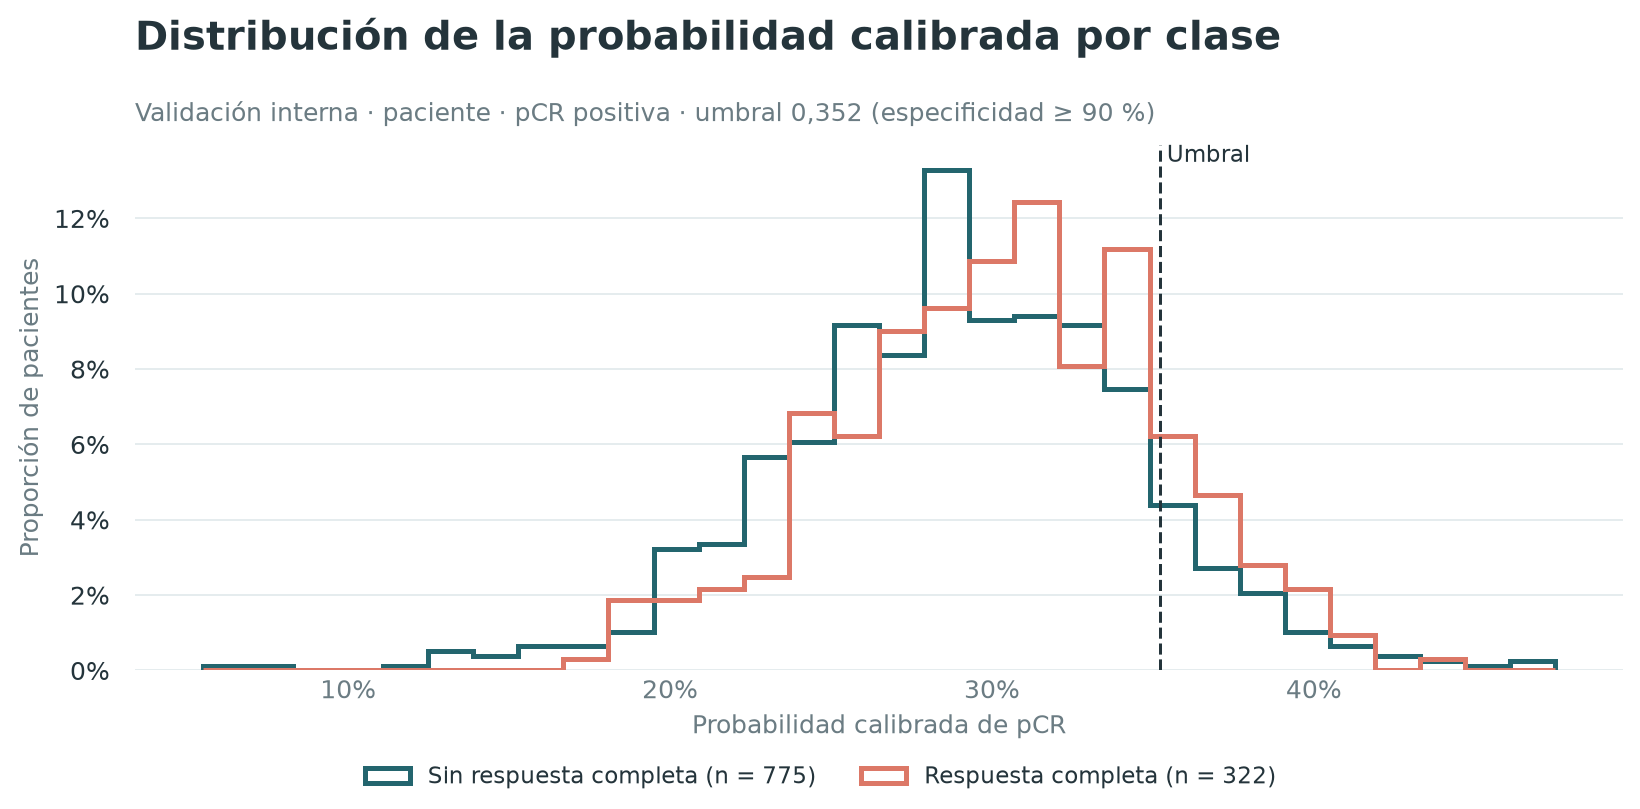

In [6]:
show(
    plot_score_distribution(scores["label"], scores["calibrated"], threshold),
    "score_distribution_nested_validation_patient",
)

## AUC dentro de cada cohorte

El AUC dentro de una cohorte compara solo pacientes de esa cohorte, de modo que la identidad de la cohorte no aporta discriminación. Se agrupan los cinco folds porque I-SPY1 tiene pocas pacientes con pCR por fold; con 26 pacientes con pCR en I-SPY1 y 44 en Duke, la incertidumbre de esos AUC es grande.

In [7]:
by_cohort = scores.groupby("cohort").apply(
    lambda rows: pd.Series(
        {
            "patients": len(rows),
            "pcr": rows["label"].sum(),
            "auc": roc_auc_score(rows["label"], rows["probability"]),
            **{
                key: value
                for key, value in binary_metrics(
                    rows["label"], rows["calibrated"], threshold
                ).items()
                if key in ("sensitivity", "specificity")
            },
        }
    ),
    include_groups=False,
)
display(by_cohort.round(3))

,patients,pcr,auc,sensitivity,specificity
cohort,,,,,
duke,209.0,44.0,0.500,0.045,0.970
spy1,104.0,26.0,0.667,0.038,0.987
spy2,784.0,252.0,0.564,0.179,0.867
